# Exercise 2 - Image Denoising

## Reusable evaluation workflow

This notebook evaluates Mean, Median, Weighted Median, and Gaussian filters on every noisy image in the supplied manifest. It tests 3x3, 5x5, and 7x7 kernels, reports Gaussian sigma, compares every result with the clean reference using PSNR, and records runtime.

It also evaluates the full synthetic image and its smooth, edge, and texture ROIs. Filters are always applied to the complete noisy image; ROI masks are used only for scoring.

## 1. Install dependencies

Run once in this notebook environment. Restart the kernel if prompted.

In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports, paths, and tunable settings

The kernel can start from this answer folder or the project root. Adjust Gaussian sigma values here; each chosen value will be recorded in results.csv.

In [2]:
from pathlib import Path
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current = Path.cwd()
PROJECT_ROOT = next(
    (folder for folder in (current, *current.parents)
     if (folder / "2 Denoising" / "Input" / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project folder containing '2 Denoising/Input/data'.")

DATA_ROOT = PROJECT_ROOT / "2 Denoising" / "Input" / "data"
ANSWER_ROOT = PROJECT_ROOT / "2 Denoising"
OUTPUT_ROOT = ANSWER_ROOT / "outputs"
KERNEL_SIZES = (3, 5, 7)
GAUSSIAN_SIGMA_BY_KERNEL = {3: 0.8, 5: 1.2, 7: 1.6}  # Tune Gaussian smoothing
WEIGHTED_MEDIAN_SIGMA_SCALE = 0.45  # Spatial weight spread relative to kernel size
RESULT_COLUMNS = [
    "clean_image", "noisy_image", "noise_type", "noise_parameters",
    "filter_name", "filter_parameters", "noisy_psnr_db",
    "filtered_psnr_db", "improvement_db", "runtime_ms",
]
MANIFEST = pd.read_csv(DATA_ROOT / "base_manifest.csv")
print(f"Manifest cases: {len(MANIFEST)}")
print(f"Kernel sizes: {KERNEL_SIZES}")
print(f"Gaussian sigma by kernel: {GAUSSIAN_SIGMA_BY_KERNEL}")

Manifest cases: 20
Kernel sizes: (3, 5, 7)
Gaussian sigma by kernel: {3: 0.8, 5: 1.2, 7: 1.6}


## 3. Reusable loading, filtering, and metric functions

PSNR always compares an image with the clean reference. Both inputs are converted to floating point before subtraction. For a regional score, the mask selects pixels only after filtering.

In [3]:
def load_gray(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    return image

def psnr(reference, estimate, mask=None):
    reference = np.asarray(reference, dtype=np.float32)
    estimate = np.asarray(estimate, dtype=np.float32)
    if reference.shape != estimate.shape:
        raise ValueError("Reference and estimate must have identical shapes.")
    if mask is not None:
        valid = np.asarray(mask) > 0
        if valid.shape != reference.shape or not np.any(valid):
            raise ValueError("ROI mask must match the image and include at least one pixel.")
        difference = reference[valid] - estimate[valid]
    else:
        difference = reference - estimate
    mse = float(np.mean(np.square(difference)))
    if mse == 0:
        return float("inf")
    return float(10.0 * np.log10((255.0 ** 2) / mse))

def weighted_median_filter(image, kernel_size, sigma_scale=WEIGHTED_MEDIAN_SIGMA_SCALE):
    radius = kernel_size // 2
    padded = np.pad(image, radius, mode="edge")
    coords = np.arange(kernel_size, dtype=np.float32) - radius
    xx, yy = np.meshgrid(coords, coords)
    sigma = max(kernel_size * sigma_scale, 1e-6)
    weights = np.exp(-(xx**2 + yy**2) / (2 * sigma**2)).ravel()
    half_weight = weights.sum() / 2.0
    output = np.empty_like(image)

    # Process one row at a time to keep memory use bounded.
    for y in range(image.shape[0]):
        windows = np.lib.stride_tricks.sliding_window_view(
            padded[y:y + kernel_size, :], (kernel_size, kernel_size)
        )[0].reshape(image.shape[1], -1)
        order = np.argsort(windows, axis=1)
        sorted_values = np.take_along_axis(windows, order, axis=1)
        sorted_weights = weights[order]
        median_index = (np.cumsum(sorted_weights, axis=1) >= half_weight).argmax(axis=1)
        output[y] = sorted_values[np.arange(image.shape[1]), median_index]
    return output

def apply_filter(noisy, filter_name, kernel_size, sigma=None):
    if kernel_size not in KERNEL_SIZES:
        raise ValueError(f"Unsupported kernel size: {kernel_size}")
    if filter_name == "mean":
        return cv2.blur(noisy, (kernel_size, kernel_size))
    if filter_name == "median":
        return cv2.medianBlur(noisy, kernel_size)
    if filter_name == "weighted_median":
        return weighted_median_filter(noisy, kernel_size)
    if filter_name == "gaussian":
        if sigma is None or sigma < 0:
            raise ValueError("Gaussian filtering requires a non-negative sigma.")
        return cv2.GaussianBlur(noisy, (kernel_size, kernel_size), sigmaX=sigma, sigmaY=sigma)
    raise ValueError(f"Unknown filter: {filter_name}")

## 4. Run the required experiments

For each manifest case, calculate noisy-image PSNR once. Then apply all four filters at every required kernel size. Runtime measures the filtering call only. Gaussian sigma is included in the recorded parameters.

In [4]:
records = []
regional_records = []
case_outputs = {}

for row in MANIFEST.itertuples(index=False):
    clean_path = DATA_ROOT / "clean" / row.clean_file
    noisy_path = DATA_ROOT / "noisy" / row.noisy_file
    clean = load_gray(clean_path)
    noisy = load_gray(noisy_path)
    if clean.shape != noisy.shape:
        raise ValueError(f"Shape mismatch for {row.noisy_file}")

    noisy_score = psnr(clean, noisy)
    outputs_for_case = []
    for filter_name in ("mean", "median", "weighted_median", "gaussian"):
        for kernel_size in KERNEL_SIZES:
            sigma = GAUSSIAN_SIGMA_BY_KERNEL[kernel_size] if filter_name == "gaussian" else None
            parameters = {"kernel_size": kernel_size}
            if sigma is not None:
                parameters["sigma"] = sigma
            if filter_name == "weighted_median":
                parameters["spatial_sigma_scale"] = WEIGHTED_MEDIAN_SIGMA_SCALE
            start = time.perf_counter()
            filtered = apply_filter(noisy, filter_name, kernel_size, sigma)
            runtime_ms = (time.perf_counter() - start) * 1000.0
            filtered_score = psnr(clean, filtered)
            records.append({
                "clean_image": row.clean_file,
                "noisy_image": row.noisy_file,
                "noise_type": row.noise_family,
                "noise_parameters": row.parameters,
                "filter_name": filter_name,
                "filter_parameters": str(parameters),
                "noisy_psnr_db": noisy_score,
                "filtered_psnr_db": filtered_score,
                "improvement_db": filtered_score - noisy_score,
                "runtime_ms": runtime_ms,
            })
            outputs_for_case.append((filtered_score, filter_name, kernel_size, sigma, parameters, filtered))

    case_outputs[row.noisy_file] = (clean, noisy, outputs_for_case)

results_df = pd.DataFrame(records, columns=RESULT_COLUMNS)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
results_path = OUTPUT_ROOT / "results.csv"
results_df.to_csv(results_path, index=False)
print(f"Saved {len(results_df)} rows to {results_path}")

Saved 240 rows to c:\Users\ADMIN\OneDrive\Desktop\Image Processing 1st Project- Ehsan Shafiei\2 Denoising\outputs\results.csv


## 5. Regional PSNR and ROI-balanced selection for synthetic_regions

Each filter is applied to the complete noisy image. The smooth, edge, and texture ROI masks are used to score each full-image result. In addition to the usual full-image PSNR winner, the notebook selects a separate ROI-balanced candidate by maximizing the lowest regional PSNR, then the mean regional PSNR. This helps avoid choosing a filter that performs well overall while damaging one important region. No pixels are copied from the reference or assembled region by region.

White mask pixels are included in each regional score; black pixels are ignored.

In [5]:
ROI_NAMES = ("smooth", "edge", "texture")
synthetic_cases = MANIFEST[MANIFEST["clean_file"] == "synthetic_regions.png"]
roi_balanced_best = {}
roi_selection_records = []

for row in synthetic_cases.itertuples(index=False):
    clean, noisy, outputs_for_case = case_outputs[row.noisy_file]
    roi_masks = {
        name: load_gray(DATA_ROOT / "roi_masks" / f"{name}.png")
        for name in ROI_NAMES
    }
    if any(mask.shape != clean.shape for mask in roi_masks.values()):
        raise ValueError(f"ROI mask shape mismatch for {row.noisy_file}")

    regional_records.append({
        "noisy_image": row.noisy_file, "filter_name": "none",
        "filter_parameters": "none", "region": "full",
        "psnr_db": psnr(clean, noisy),
    })
    for region, mask in roi_masks.items():
        regional_records.append({
            "noisy_image": row.noisy_file, "filter_name": "none",
            "filter_parameters": "none", "region": region,
            "psnr_db": psnr(clean, noisy, mask),
        })

    candidates = []
    for score, filter_name, kernel_size, sigma, params, filtered in outputs_for_case:
        regional_records.append({
            "noisy_image": row.noisy_file, "filter_name": filter_name,
            "filter_parameters": str(params), "region": "full",
            "psnr_db": psnr(clean, filtered),
        })
        region_scores = {}
        for region, mask in roi_masks.items():
            region_score = psnr(clean, filtered, mask)
            region_scores[region] = region_score
            regional_records.append({
                "noisy_image": row.noisy_file, "filter_name": filter_name,
                "filter_parameters": str(params), "region": region,
                "psnr_db": region_score,
            })
        candidates.append({
            "full_psnr_db": score, "filter_name": filter_name,
            "kernel_size": kernel_size, "sigma": sigma,
            "parameters": params, "image": filtered,
            "region_scores": region_scores,
            "worst_roi_psnr_db": min(region_scores.values()),
            "mean_roi_psnr_db": float(np.mean(list(region_scores.values()))),
        })

    # Maximize the weakest ROI first; use mean regional PSNR and then full PSNR to break ties.
    chosen = max(candidates, key=lambda item: (
        item["worst_roi_psnr_db"], item["mean_roi_psnr_db"], item["full_psnr_db"]
    ))
    roi_balanced_best[row.noisy_file] = chosen
    roi_selection_records.append({
        "noisy_image": row.noisy_file, "filter_name": chosen["filter_name"],
        "kernel_size": chosen["kernel_size"], "sigma": chosen["sigma"],
        "filter_parameters": str(chosen["parameters"]),
        "full_psnr_db": chosen["full_psnr_db"],
        "worst_roi_psnr_db": chosen["worst_roi_psnr_db"],
        "mean_roi_psnr_db": chosen["mean_roi_psnr_db"],
        **{f"{name}_psnr_db": chosen["region_scores"][name] for name in ROI_NAMES},
    })

regional_df = pd.DataFrame(regional_records)
regional_path = OUTPUT_ROOT / "regional_psnr.csv"
regional_df.to_csv(regional_path, index=False)
roi_selection_path = OUTPUT_ROOT / "roi_balanced_selection.csv"
pd.DataFrame(roi_selection_records).to_csv(roi_selection_path, index=False)
print(f"Saved regional scores to {regional_path}")
print(f"Saved ROI-balanced choices to {roi_selection_path}")

Saved regional scores to c:\Users\ADMIN\OneDrive\Desktop\Image Processing 1st Project- Ehsan Shafiei\2 Denoising\outputs\regional_psnr.csv
Saved ROI-balanced choices to c:\Users\ADMIN\OneDrive\Desktop\Image Processing 1st Project- Ehsan Shafiei\2 Denoising\outputs\roi_balanced_selection.csv


## 6. Summaries and comparisons

Compare filters across noise families, noise strengths, and kernel sizes. A higher PSNR means lower average squared error to the clean reference; it does not guarantee better edge or texture preservation.

,noise_type,filter_name,filter_parameters,mean_filtered_psnr_db,mean_improvement_db,mean_runtime_ms
9,gaussian,weighted_median,"{'kernel_size': 3, 'spatial_sigma_scale': 0.45}",26.523193,1.791776,87.69056
6,gaussian,median,{'kernel_size': 3},26.467119,1.735701,0.26135
0,gaussian,gaussian,"{'kernel_size': 3, 'sigma': 0.8}",26.181771,1.450354,0.70169
10,gaussian,weighted_median,"{'kernel_size': 5, 'spatial_sigma_scale': 0.45}",25.997318,1.265900,213.19040
7,gaussian,median,{'kernel_size': 5},25.299634,0.568217,0.57938
3,gaussian,mean,{'kernel_size': 3},24.650318,-0.081099,1.94861
1,gaussian,gaussian,"{'kernel_size': 5, 'sigma': 1.2}",24.646721,-0.084696,0.24792
11,gaussian,weighted_median,"{'kernel_size': 7, 'spatial_sigma_scale': 0.45}",24.621468,-0.109949,515.63605
8,gaussian,median,{'kernel_size': 7},23.975179,-0.756238,8.31489
2,gaussian,gaussian,"{'kernel_size': 7, 'sigma': 1.6}",23.491618,-1.239799,0.36718


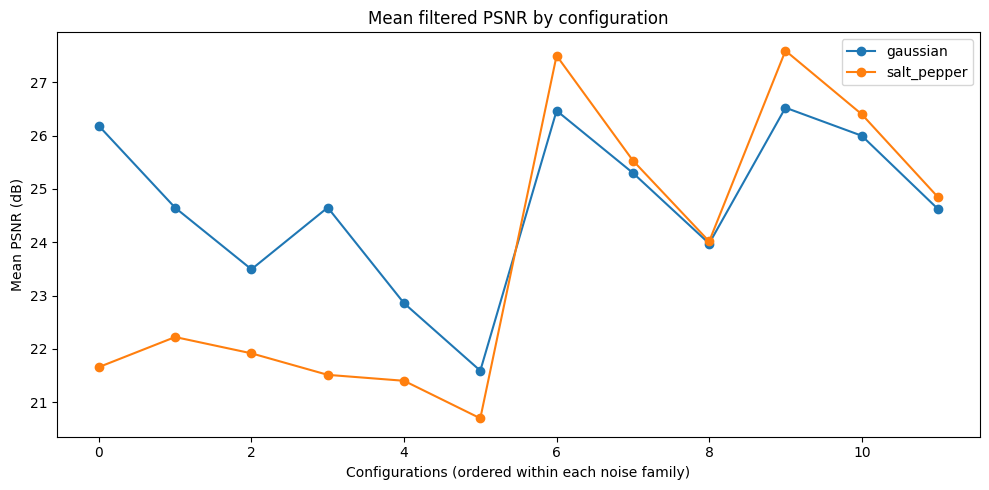

In [6]:
summary_df = (
    results_df.groupby(["noise_type", "filter_name", "filter_parameters"], as_index=False)
    .agg(mean_filtered_psnr_db=("filtered_psnr_db", "mean"),
         mean_improvement_db=("improvement_db", "mean"),
         mean_runtime_ms=("runtime_ms", "mean"))
    .sort_values(["noise_type", "mean_filtered_psnr_db"], ascending=[True, False])
)
display(summary_df)

fig, ax = plt.subplots(figsize=(10, 5))
for noise_type, group in results_df.groupby("noise_type"):
    means = group.groupby(["filter_name", "filter_parameters"])["filtered_psnr_db"].mean()
    ax.plot(range(len(means)), means.values, marker="o", label=noise_type)
ax.set(title="Mean filtered PSNR by configuration", xlabel="Configurations (ordered within each noise family)", ylabel="Mean PSNR (dB)")
ax.legend()
fig.tight_layout()
plt.show()

## 7. Save selected outputs and full-image comparisons
For every noisy input, save the highest full-image PSNR result. The comparison grid shows the entire image for the clean reference, noisy input, each tested filter, the ROI-balanced result when available, and the best full-image PSNR result last. Image aspect ratios are preserved; no crop is used.

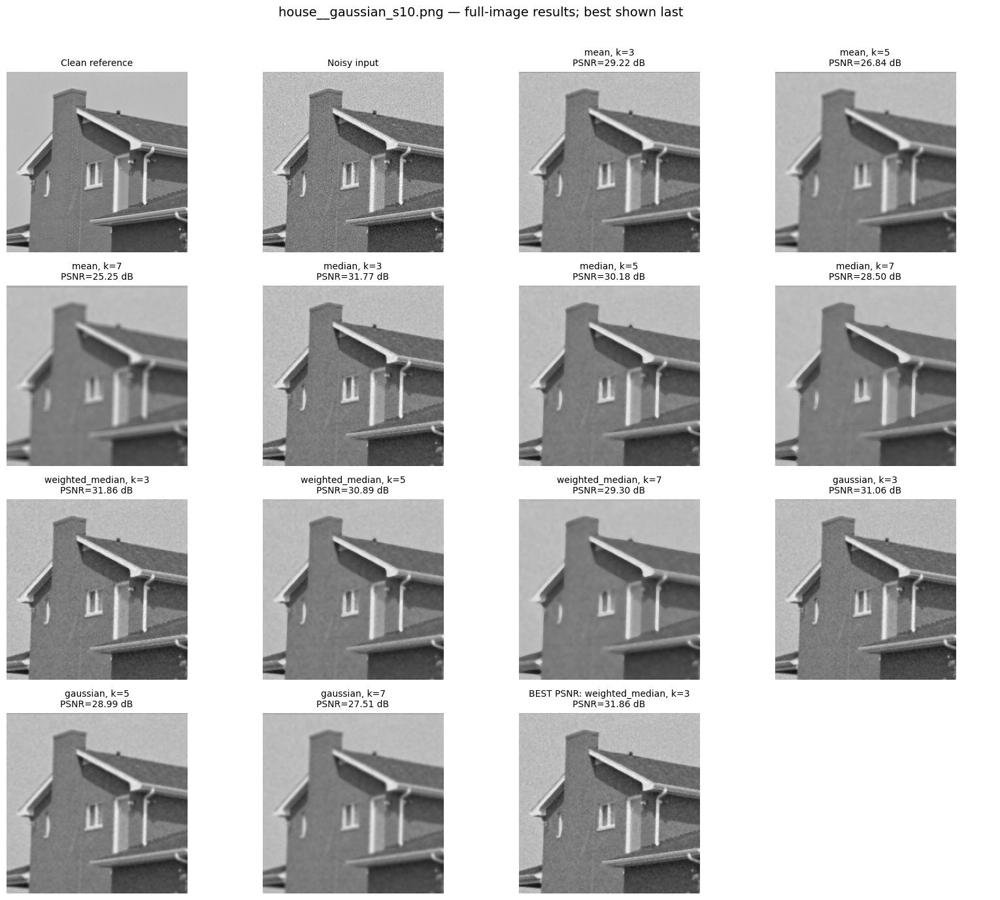

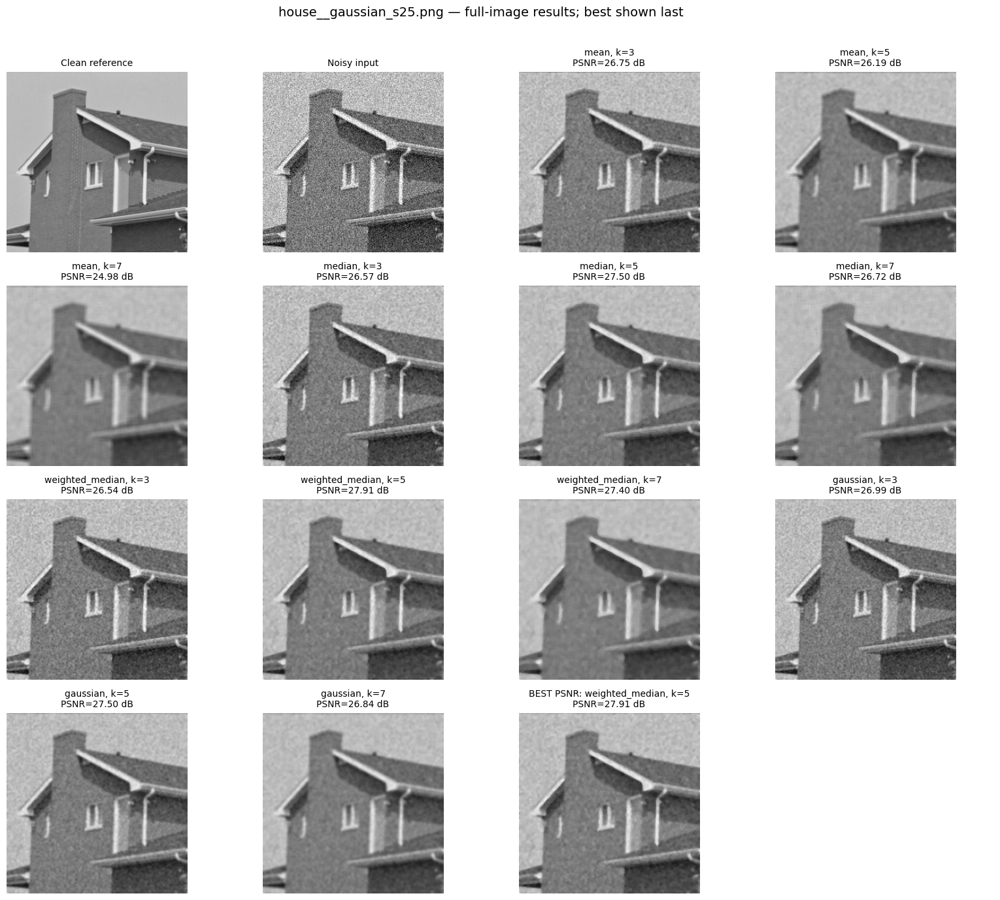

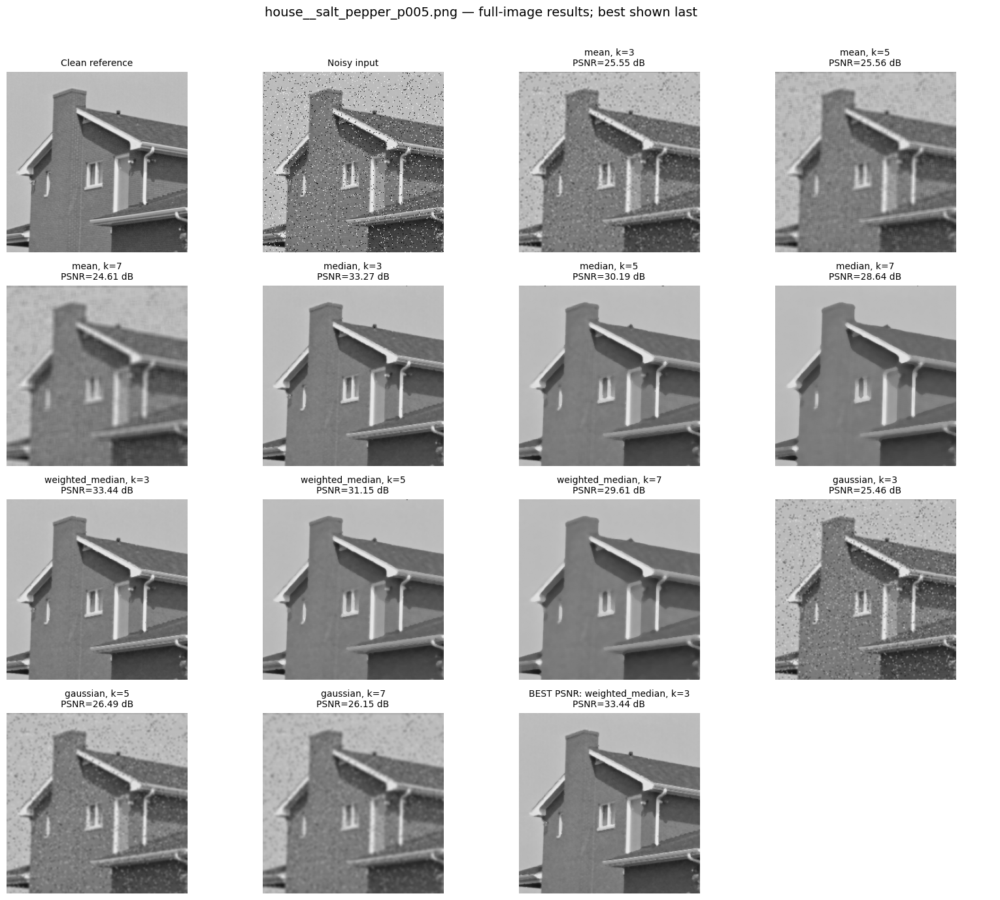

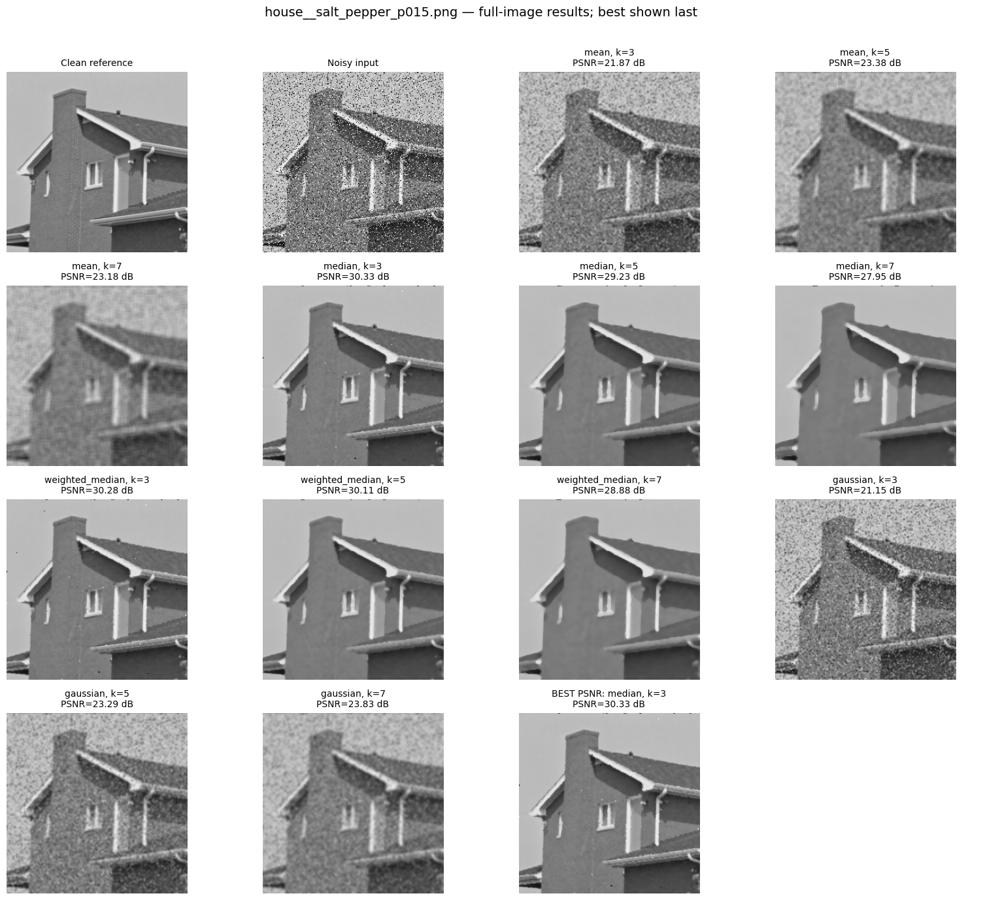

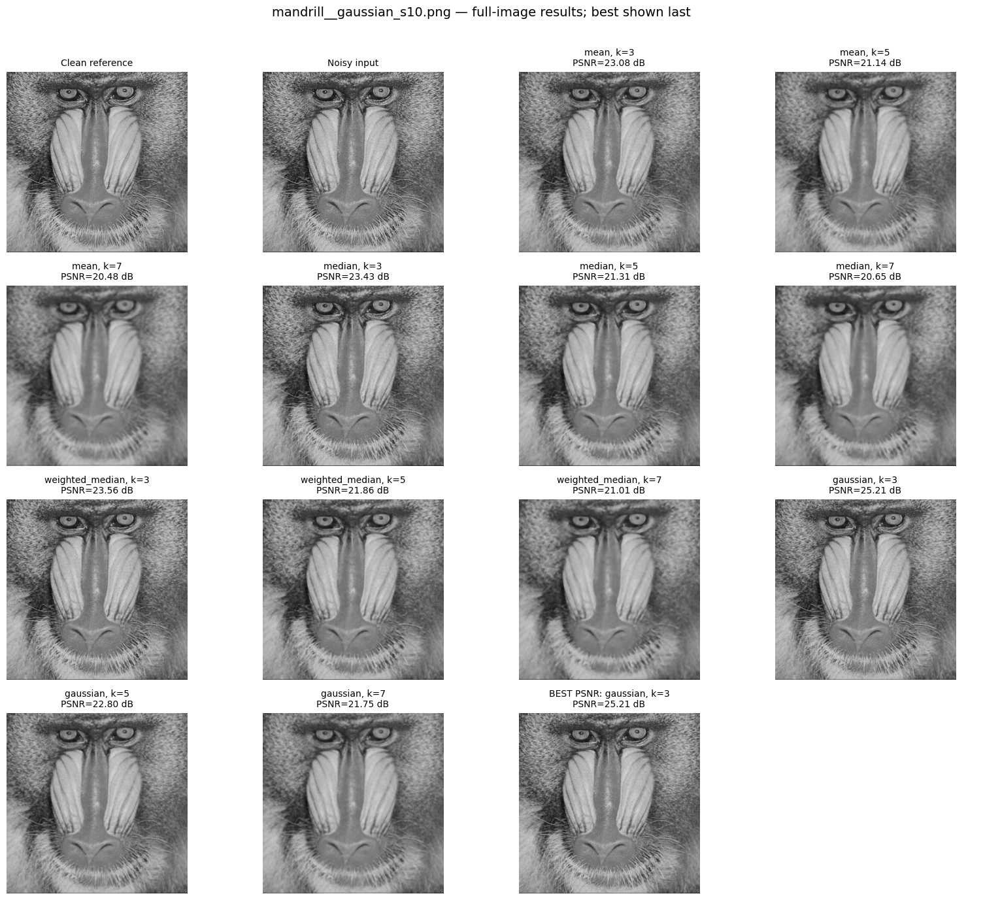

...

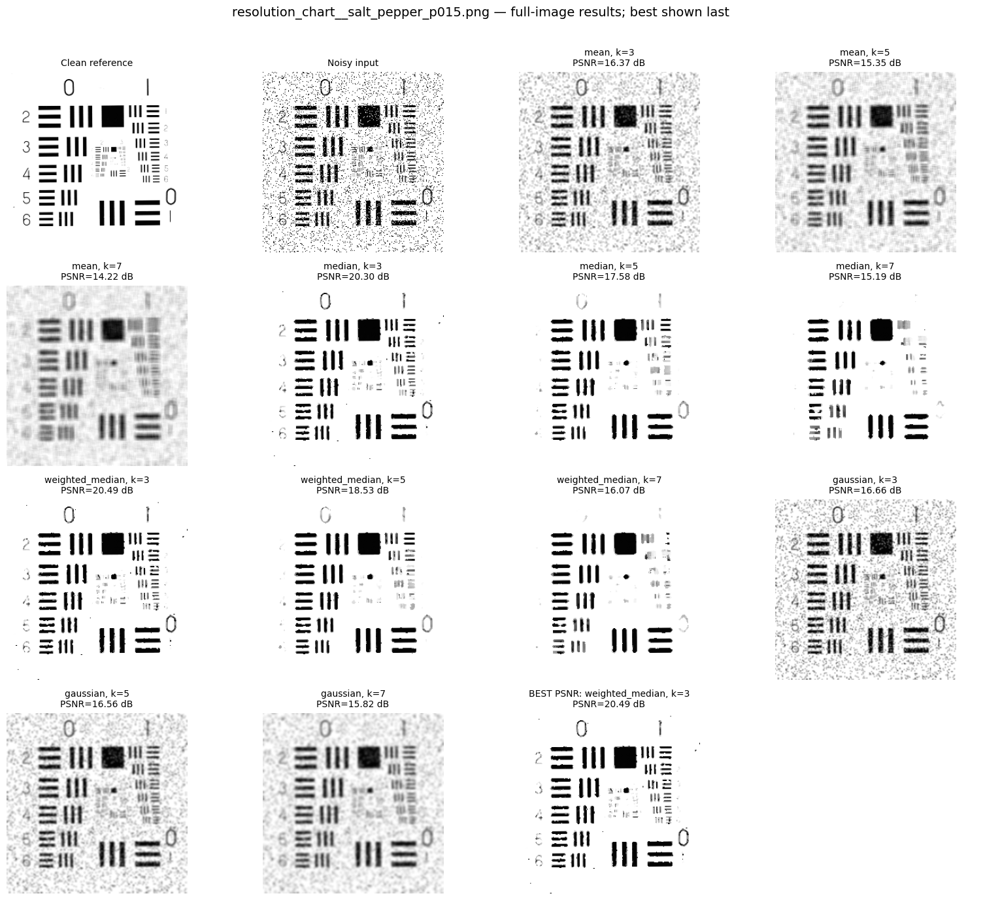

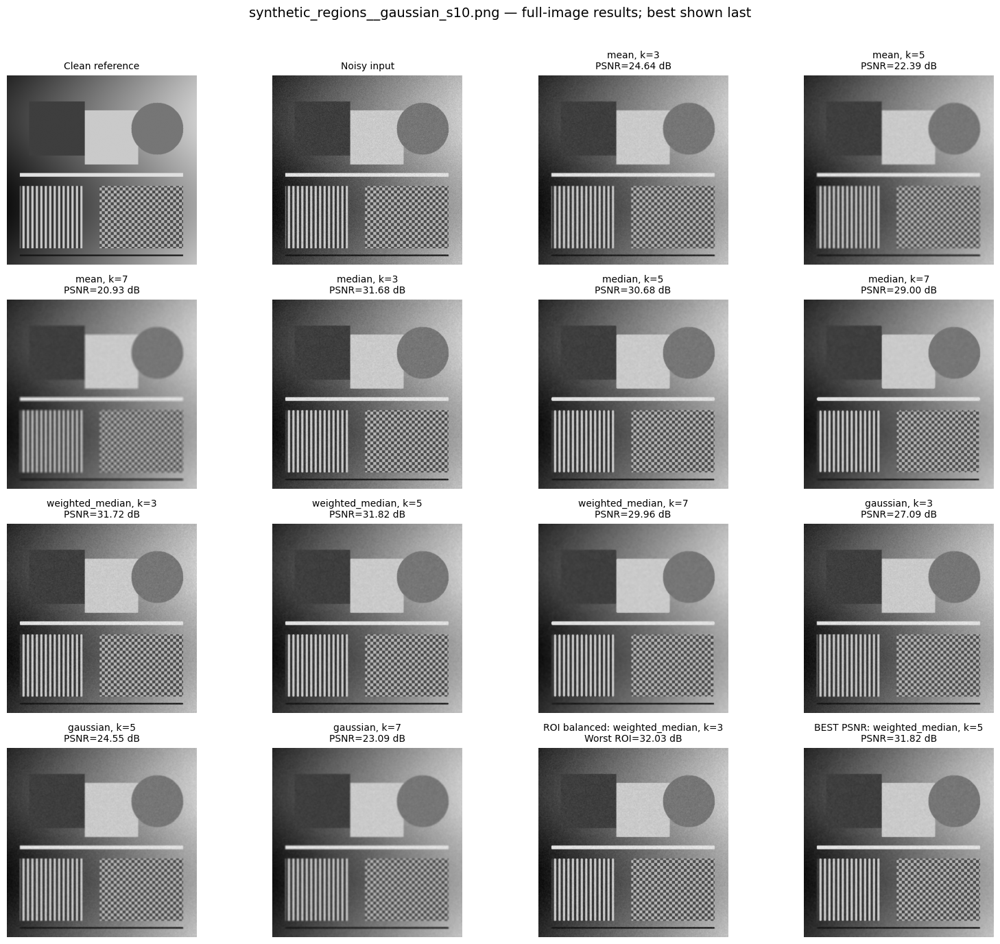

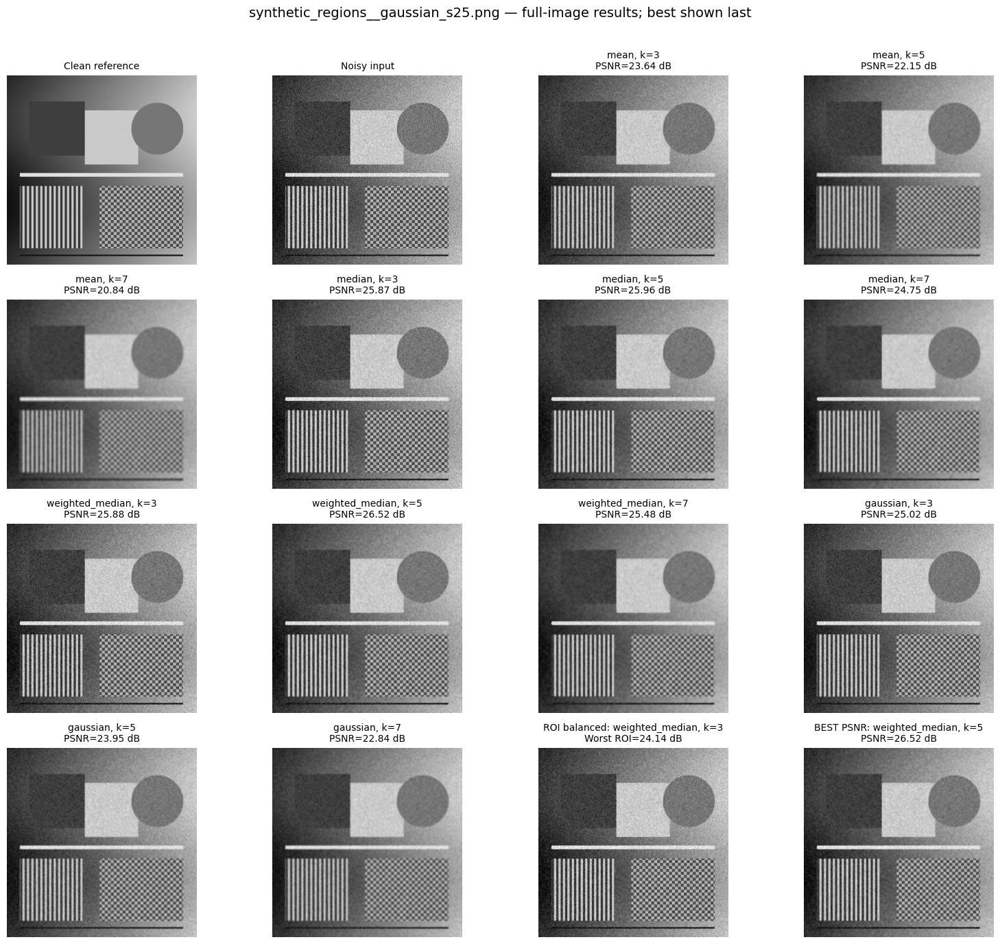

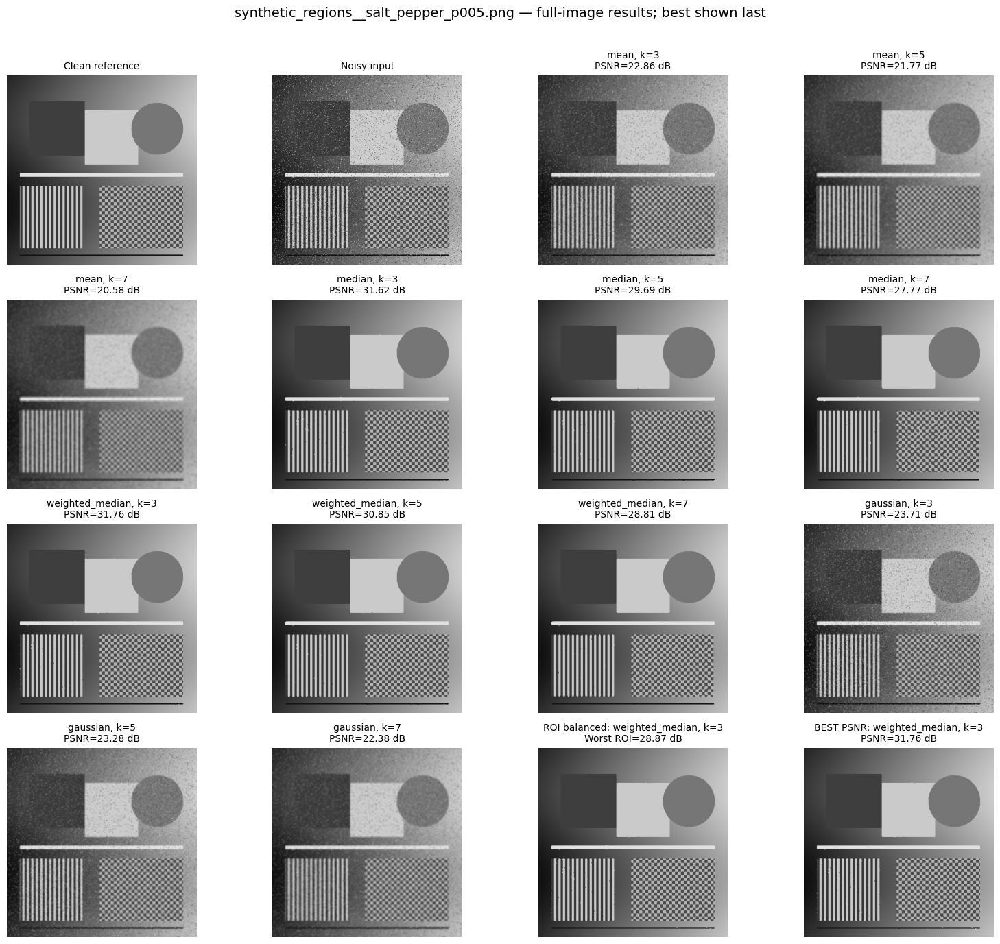

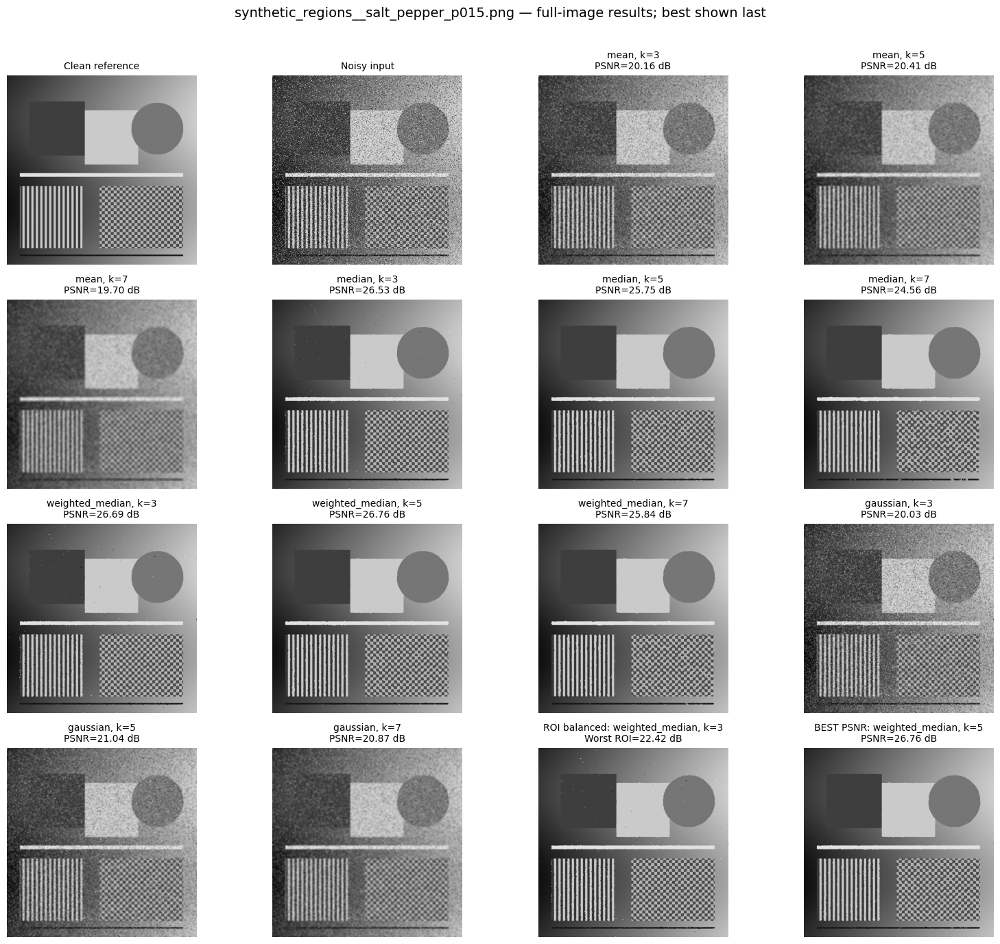

,noisy_image,best_filter,kernel_size,sigma,parameters,best_psnr_db
0,house__gaussian_s10.png,weighted_median,3,NaN,"{'kernel_size': 3, 'spatial_sigma_scale': 0.45}",31.860581
1,house__gaussian_s25.png,weighted_median,5,NaN,"{'kernel_size': 5, 'spatial_sigma_scale': 0.45}",27.905123
2,house__salt_pepper_p005.png,weighted_median,3,NaN,"{'kernel_size': 3, 'spatial_sigma_scale': 0.45}",33.436800
3,house__salt_pepper_p015.png,median,3,NaN,{'kernel_size': 3},30.327682
4,mandrill__gaussian_s10.png,gaussian,3,0.8,"{'kernel_size': 3, 'sigma': 0.8}",25.209966
5,mandrill__gaussian_s25.png,gaussian,3,0.8,"{'kernel_size': 3, 'sigma': 0.8}",23.738274
6,mandrill__salt_pepper_p005.png,weighted_median,3,NaN,"{'kernel_size': 3, 'spatial_sigma_scale': 0.45}",23.631675
7,mandrill__salt_pepper_p015.png,weighted_median,3,NaN,"{'kernel_size': 3, 'spatial_sigma_scale': 0.45}",22.850936
8,peppers__gaussian_s10.png,median,3,NaN,{'kernel_size': 3},32.078409
9,peppers__gaussian_s25.png,weighted_median,5,NaN,"{'kernel_size': 5, 'spatial_sigma_scale': 0.45}",28.643891


Full-image PSNR selections: c:\Users\ADMIN\OneDrive\Desktop\Image Processing 1st Project- Ehsan Shafiei\2 Denoising\outputs\selected_outputs
ROI-balanced selections: c:\Users\ADMIN\OneDrive\Desktop\Image Processing 1st Project- Ehsan Shafiei\2 Denoising\outputs\roi_balanced_outputs
Full-image comparison grids: c:\Users\ADMIN\OneDrive\Desktop\Image Processing 1st Project- Ehsan Shafiei\2 Denoising\outputs\comparison_crops


In [7]:
SELECTED_DIR = OUTPUT_ROOT / "selected_outputs"
ROI_SELECTED_DIR = OUTPUT_ROOT / "roi_balanced_outputs"
CROP_DIR = OUTPUT_ROOT / "comparison_crops"
SELECTED_DIR.mkdir(parents=True, exist_ok=True)
ROI_SELECTED_DIR.mkdir(parents=True, exist_ok=True)
CROP_DIR.mkdir(parents=True, exist_ok=True)
selected_rows = []

for noisy_file, (clean, noisy, outputs_for_case) in case_outputs.items():
    best_score, best_filter, best_kernel, best_sigma, best_parameters, best_image = max(outputs_for_case, key=lambda item: item[0])
    cv2.imwrite(str(SELECTED_DIR / f"{Path(noisy_file).stem}__best_{best_filter}_k{best_kernel}.png"), best_image)

    panels = [(clean, "Clean reference"), (noisy, "Noisy input")]
    for score, filter_name, kernel_size, sigma, params, filtered in outputs_for_case:
        panels.append((filtered, f"{filter_name}, k={kernel_size}\nPSNR={score:.2f} dB"))

    roi_choice = roi_balanced_best.get(noisy_file)
    if roi_choice is not None:
        roi_image = roi_choice["image"]
        roi_filename = f"{Path(noisy_file).stem}__roi_balanced_{roi_choice['filter_name']}_k{roi_choice['kernel_size']}.png"
        cv2.imwrite(str(ROI_SELECTED_DIR / roi_filename), roi_image)
        panels.append((roi_image, f"ROI balanced: {roi_choice['filter_name']}, k={roi_choice['kernel_size']}\nWorst ROI={roi_choice['worst_roi_psnr_db']:.2f} dB"))

    # Keep the global full-image PSNR winner as the final panel.
    panels.append((best_image, f"BEST PSNR: {best_filter}, k={best_kernel}\nPSNR={best_score:.2f} dB"))
    columns = 4
    rows = int(np.ceil(len(panels) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 3.5 * rows), squeeze=False)
    for ax, (panel, title) in zip(axes.flat, panels):
        ax.imshow(panel, cmap="gray", vmin=0, vmax=255, aspect="equal")
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    for ax in axes.flat[len(panels):]:
        ax.axis("off")
    fig.suptitle(f"{noisy_file} — full-image results; best shown last", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    figure_name = f"{Path(noisy_file).stem}__all_methods_then_best.png"
    fig.savefig(CROP_DIR / figure_name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    selected_rows.append({"noisy_image": noisy_file, "best_filter": best_filter, "kernel_size": best_kernel, "sigma": best_sigma, "parameters": str(best_parameters), "best_psnr_db": best_score})

display(pd.DataFrame(selected_rows))
print(f"Full-image PSNR selections: {SELECTED_DIR}")
print(f"ROI-balanced selections: {ROI_SELECTED_DIR}")
print(f"Full-image comparison grids: {CROP_DIR}")